In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df = pd.read_pickle('pilot_2_results.pkl')

In [3]:
#subjects_decisions contains subject decisions for each subject
#the first column contains number of accumulated wins, the second contains accumulated fails
#the third is boolean and contains 1 if subject decided to change the button and 0 if subject decided to stay
#the fourth contains the number of remaining presses
subjects_decisions = []
#subjects_button_activity contains accumulated buttons wins, fails and remaining presses for all the subjects per button
subjects_button_activity = []
for subject in df['press_data']:
    record = np.array([[el['button_number'],el['outcome']] for el in subject])
    button_split = [record[record[:,0]==k,1] for k in np.unique(record[:,0])]
    decisions = [np.vstack([np.cumsum(elt),
                                np.arange(1,len(elt)+1)-np.cumsum(elt),
                                np.eye(1,M=len(elt),k=len(elt)-1)]).T for elt in button_split]
    button_split_pos = np.cumsum([len(el) for el in decisions])[:-1]
    decisions = np.concatenate(decisions)
    decisions = np.c_[decisions, np.arange(len(decisions))[::-1]]
    subjects_decisions.append(decisions[:-1])
    subjects_button_activity.append(np.split(decisions[:,[0,1,3]], button_split_pos))
    
decisions = np.concatenate(subjects_decisions)
decisions = decisions[np.lexsort((decisions[:,3], decisions[:,2], decisions[:,1], decisions[:,0]))].astype(int)

In [4]:
first_button_switch = np.array([el[0][-1] for el in subjects_button_activity])

In [5]:
print(first_button_switch[first_button_switch[:,1] > first_button_switch[:,0]][:,:2])

[[ 1.  3.]
 [ 4.  6.]
 [ 0.  1.]
 [ 0.  3.]
 [ 0.  4.]
 [ 0.  6.]
 [ 0.  1.]
 [ 3. 10.]
 [ 2.  4.]
 [ 2.  4.]
 [ 0. 13.]
 [ 1.  4.]
 [ 7. 23.]
 [ 6.  9.]
 [ 1.  2.]
 [ 2.  5.]
 [ 1.  2.]
 [ 3.  7.]
 [ 2.  5.]
 [ 1.  3.]
 [ 0.  3.]
 [ 0.  1.]
 [ 1.  3.]
 [ 0.  2.]
 [ 1.  4.]
 [ 1.  4.]]


In [6]:
print(np.array([el[-1][-1] for el in subjects_button_activity])[:,:2])

[[65.  5.]
 [84. 12.]
 [ 5.  2.]
 [31. 11.]
 [76. 14.]
 [ 0.  1.]
 [44.  6.]
 [19.  2.]
 [31.  5.]
 [48. 11.]
 [14.  4.]
 [60. 10.]
 [58. 42.]
 [ 9.  0.]
 [61. 15.]
 [ 4.  0.]
 [74. 11.]
 [47.  8.]
 [58. 14.]
 [87. 13.]
 [54. 16.]
 [72.  3.]
 [ 1.  0.]
 [19.  5.]
 [11.  5.]
 [72. 24.]
 [49.  7.]
 [62. 13.]
 [33. 20.]
 [ 7.  3.]
 [80. 20.]
 [14. 11.]
 [ 1.  0.]
 [81. 11.]
 [79. 21.]
 [28. 13.]
 [29.  6.]
 [ 0.  9.]
 [69. 31.]
 [ 0.  3.]
 [81.  6.]
 [29. 13.]
 [29.  5.]
 [16.  9.]
 [61. 39.]
 [82. 16.]
 [17.  8.]
 [61. 20.]]


Total number of stay decisions is 2955
Total number of leave decisions is 60


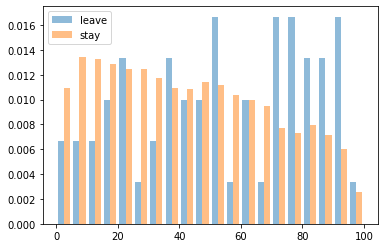

In [7]:
wins_more_fails = decisions[np.logical_and(decisions[:,0] > decisions[:,1], decisions[:,1] > 0)]
#wins_more_fails = decisions[np.logical_and(decisions[:,0] == 2*decisions[:,1], decisions[:,1] > 0)]
wmf_stay = wins_more_fails[wins_more_fails[:,2] == 0]
wmf_leave = wins_more_fails[wins_more_fails[:,2] == 1]

print("Total number of stay decisions is " + str(len(wmf_stay)))
print("Total number of leave decisions is " + str(len(wmf_leave)))

plt.hist([wmf_leave[:,3], wmf_stay[:,3]], alpha=0.5, label=["leave", "stay"], range=[0.0, 100.0], bins=20, density=True)
plt.legend(loc="upper left")
plt.show()

In [8]:
out1, out2 = np.unique(decisions[:,:2], axis=0, return_counts=True)
total_counts = np.c_[out1, out2]

In [9]:
print(total_counts[total_counts[:,0]<10])

[[  0   1 228]
 [  0   2  98]
 [  0   3  62]
 [  0   4  35]
 [  0   5  23]
 [  0   6  17]
 [  0   7  14]
 [  0   8  10]
 [  0   9   9]
 [  0  10   7]
 [  0  11   3]
 [  0  12   1]
 [  0  13   1]
 [  1   0 169]
 [  1   1 119]
 [  1   2  66]
 [  1   3  32]
 [  1   4  14]
 [  1   5   4]
 [  1   6   4]
 [  1   7   1]
 [  1   8   1]
 [  1   9   1]
 [  1  11   2]
 [  1  12   2]
 [  1  13   2]
 [  1  14   2]
 [  1  15   1]
 [  1  16   1]
 [  2   0  78]
 [  2   1  68]
 [  2   2  52]
 [  2   3  32]
 [  2   4  18]
 [  2   5   9]
 [  2   6   4]
 [  2   7   4]
 [  2   8   4]
 [  2   9   2]
 [  2  10   1]
 [  2  11   1]
 [  2  12   1]
 [  2  13   1]
 [  2  14   1]
 [  2  15   1]
 [  3   0  52]
 [  3   1  56]
 [  3   2  46]
 [  3   3  34]
 [  3   4  18]
 [  3   5   9]
 [  3   6   3]
 [  3   7   3]
 [  3   8   2]
 [  3   9   3]
 [  3  10   2]
 [  3  11   1]
 [  3  12   1]
 [  3  13   2]
 [  3  14   1]
 [  4   0  33]
 [  4   1  36]
 [  4   2  32]
 [  4   3  28]
 [  4   4  20]
 [  4   5  17]
 [  4   6 

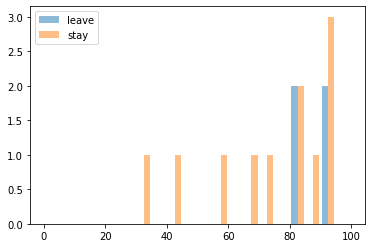

In [10]:
wins, fails = 6, 4
choise = decisions[np.logical_and(decisions[:,0]==wins,decisions[:,1]==fails)][:,2:]
leave = choise[choise[:,0]==1][:,1]
stay = choise[choise[:,0]==0][:,1]

plt.hist([leave, stay], alpha=0.5, label=["leave", "stay"], range=[0.0, 100.0], bins=20)
plt.legend(loc="upper left")
plt.show()

The average number of buttons explored is 8.333333333333334
The average reward received is 64.27083333333333
Out of 48 subjects in total 33 subjects (or 68.75%) got the largest contribution from the last button
The average contribution of the button with the largest contribution is 69.14 %


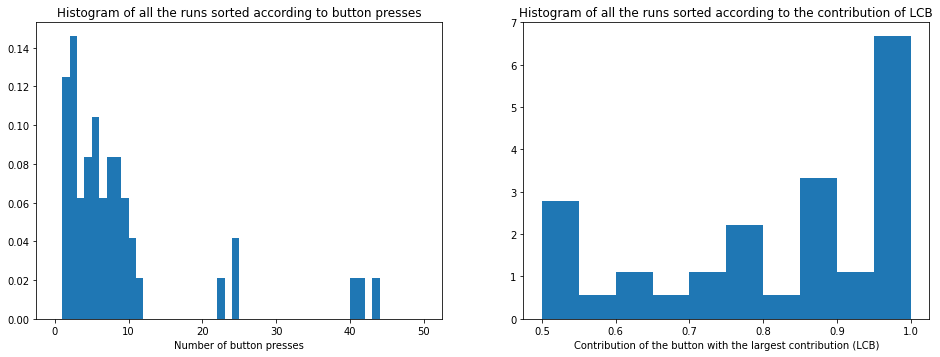

In [11]:
#Contribution (number of wins) for each button for each subject
contributions = [[el[-1,0] for el in subject] for subject in subjects_button_activity]
#Total number of button pressed
num_buttons = np.array([len(subject) for subject in contributions], dtype=np.int)
#Index of the button with largest contribution
max_button_index = np.array([subject.index(max(subject)) for subject in contributions], dtype=np.int)
#Number of runs where the final button was the button with the largest contribution
num_last_largest_contr = np.count_nonzero(max_button_index==(num_buttons-1))
#Ratio of largest button contribution to total contribution
top_button_to_all = np.array([max(subject)/sum(subject) for subject in contributions])

print("The average number of buttons explored is " + str(np.sum(num_buttons)/len(num_buttons)))
print("The average reward received is " + str(np.sum([sum(subject) for subject in contributions])/len(contributions)))
print("Out of " + str(len(contributions)) + " subjects in total " + str(num_last_largest_contr) + 
            " subjects (or " + "%.2f" % (100*num_last_largest_contr/len(contributions)) + 
              "%) got the largest contribution from the last button")
print("The average contribution of the button with the largest contribution is " + 
          "%4.2f" % (100*np.mean(top_button_to_all)) + " %")

fig = plt.figure(figsize=(16,12))
ax = fig.add_subplot(221)
ax.set_title("Histogram of all the runs sorted according to button presses")
ax.set_xlabel("Number of button presses")
ax.hist(num_buttons, density=True, bins=50, range=(0, 50));

ax = fig.add_subplot(222)
ax.set_title("Histogram of all the runs sorted according to the contribution of LCB")
ax.set_xlabel("Contribution of the button with the largest contribution (LCB)")
ax.hist(top_button_to_all, density=True, bins=10, range=(0.5,1));

In [12]:
#measuring practice round average button press time and number of presses
practice_times = []
for subject in df['practice_data']:
    button_times = []
    button_times = [1.0e-3 * el['press_time'] for el in subject]
    practice_times.append(button_times)
    
practice_presses = np.array([len(subject) for subject in practice_times], dtype = np.int)
total_practice_round_time = np.array([sum(subject) if len(subject) > 0 else 0 for subject in practice_times])
average_press_times = np.array([sum(subject)/len(subject) if len(subject) > 0 else 0 for subject in practice_times])

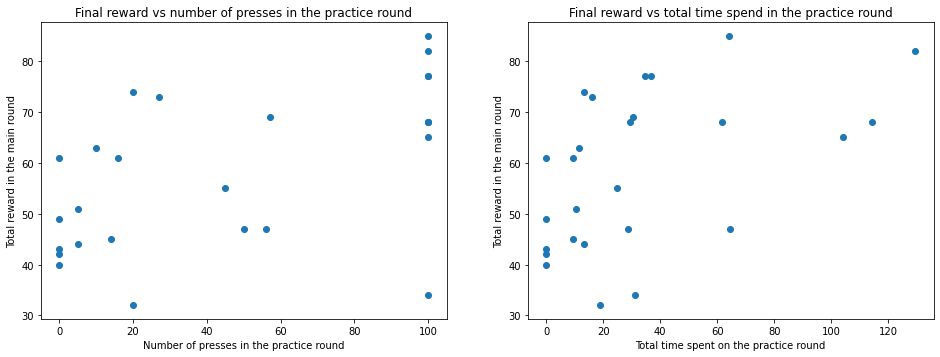

In [13]:
fails_positions = first_button_switch[:,1] > first_button_switch[:,0]

fig = plt.figure(figsize=(16,12))
ax = fig.add_subplot(221)
ax.set_title("Final reward vs number of presses in the practice round")
ax.set_xlabel("Number of presses in the practice round")
ax.set_ylabel("Total reward in the main round")
ax.scatter(practice_presses[fails_positions], df['total_win'].values[fails_positions])

ax = fig.add_subplot(222)
ax.set_title("Final reward vs total time spend in the practice round")
ax.set_xlabel("Total time spent on the practice round")
ax.set_ylabel("Total reward in the main round")
ax.scatter(total_practice_round_time[fails_positions], df['total_win'].values[fails_positions]);

plt.show()